# Spread plots for every completed trade

Each plot shows **formation**, **trading**, and **six months after trading ends**. We keep the original model fixed throughout, so the later line shows what happened to the same spread.

- **Green triangle:** actual entry.
- **Blue square:** actual exit.
- **Red X:** stop-loss signal, if the trade stopped out. The exit normally happens at the next close and can have a different spread value.
- Dashed horizontal lines show entry and exit thresholds; red lines show stop thresholds.

The spread is `log(A price) − beta × log(B price)`, using adjusted prices and the saved beta. Its mean and standard deviation come only from formation. A falling spread is not automatically a losing trade: the trade may be long or short the spread.

**Later prices are retrospective only.** Some six-month follow-ups cross into the reserved holdout, beginning 2023-08-25. Inspecting these uses that portion of the holdout for research; it should no longer count as untouched validation data. This notebook does not refit or rerun trades.

The next cell loads the same saved winning strategy as notebook 6.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RUN_ID = None  # Set explicitly if more than one saved search exists.
base = ROOT / 'outputs' / 'joint_grid_search_zero_cost'
runs = sorted(p.parent for p in base.glob('*/grid_summary.csv'))
if RUN_ID is None:
    if len(runs) != 1:
        raise ValueError(f'Set RUN_ID to one of {[p.name for p in runs]}')
    run = runs[0]
else:
    run = base / RUN_ID
summary = pd.read_csv(run / 'grid_summary.csv')
complete = summary.loc[summary['Status'].eq('complete') & np.isfinite(summary['Sharpe Ratio'])]
if complete.empty:
    raise ValueError('No completed strategy with finite Sharpe ratio.')
winner = complete.sort_values('Sharpe Ratio', ascending=False, kind='stable').iloc[0]
folder = run / Path(winner['Output Folder']).name
params = json.loads((folder / 'parameters.json').read_text())
assert params['cost_bps_per_leg'] == 0
initial = params['initial_capital']
print(f'Run: {run.name}; completed combinations: {len(complete)} / {len(summary)}')
print('Selected parameters:', params)
portfolio = pd.read_csv(folder / 'portfolio_daily.csv', parse_dates=['Date']).set_index('Date').sort_index()
trades = pd.read_csv(folder / 'trades.csv')
for col in ['Entry Signal Date', 'Entry Date', 'Exit Signal Date', 'Exit Date']:
    trades[col] = pd.to_datetime(trades[col])
assert portfolio.index.is_unique and portfolio.index.max() < pd.Timestamp('2023-08-25')
assert trades[['Entry Date', 'Exit Date']].notna().all().all()
assert trades['Exit Date'].ge(trades['Entry Date']).all()
trades['Entry Year'] = trades['Entry Date'].dt.year
trades['Exit Year'] = trades['Exit Date'].dt.year
trades['Pair'] = [' / '.join(sorted((a, b))) for a, b in zip(trades.A, trades.B)]

Run: cb64c19613e1e11beb71; completed combinations: 1248 / 1248
Selected parameters: {'formation_months': 18, 'trading_months': 6, 'correlation_threshold': 0.8, 'eg_significance': 0.01, 'entry_z': 1.5, 'exit_z': 0.5, 'stop_z': 4.0, 'run_id': 'cb64c19613e1e11beb71', 'cost_bps_per_leg': 0.0, 'initial_capital': 100000.0}


## Save the plots

By default we plot **all completed trades**. Set `TRADE_SCOPE = 'stop_loss'` for only stopped trades, or `'losing'` for only losing trades.

Each trade gets a separate PNG. A PDF collects all plots, and an index CSV links each trade to its file. We show only one preview here to keep the notebook short.

The x-axis labels identify the last calendar date of each period. Shaded regions distinguish formation, trading, and follow-up. A black dotted line marks the holdout boundary when visible. Missing prices appear as gaps, rather than being filled.

In [2]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.backends.backend_pdf import PdfPages
from functools import lru_cache

TRADE_SCOPE = 'all'  # 'all', 'stop_loss', or 'losing'
assert TRADE_SCOPE in {'all', 'stop_loss', 'losing'}
sample = trades.copy()
if TRADE_SCOPE == 'stop_loss':
    sample = sample.loc[sample['Exit Reason'].eq('Stop loss')]
elif TRADE_SCOPE == 'losing':
    sample = sample.loc[sample['Net P/L ($)'].lt(0)]
sample = sample.sort_values(['Window', 'A', 'B', 'Entry Date']).reset_index(drop=True)
windows = pd.read_csv(folder / 'window_summary.csv').set_index('Window')
for name in ['Formation Start', 'Formation End Exclusive', 'Trading Start', 'Trading End Exclusive']:
    windows[name] = pd.to_datetime(windows[name])
out = ROOT / 'outputs' / 'trade_spread_plots_zero_cost' / run.name / folder.name / TRADE_SCOPE
out.mkdir(parents=True, exist_ok=True)
HOLDOUT_START = pd.Timestamp('2023-08-25')

@lru_cache(maxsize=None)
def prices(source, ticker):
    path = ROOT / 'data' / source / f'{ticker}.csv'
    frame = pd.read_csv(path, usecols=['Date', 'Adj Close'])
    frame['Date'] = pd.to_datetime(frame['Date'])
    assert not frame['Date'].duplicated().any(), f'Duplicate dates: {path}'
    values = pd.to_numeric(frame.set_index('Date')['Adj Close'], errors='coerce').sort_index()
    return values.where(np.isfinite(values) & values.gt(0))

records = []
preview_path = None
with PdfPages(out / 'trade_spreads.pdf') as pdf:
    for number, trade in sample.iterrows():
        window = windows.loc[trade['Window']]
        start = window['Formation Start']
        trade_start = window['Trading Start']
        trade_end = window['Trading End Exclusive']
        post_end = trade_end + pd.DateOffset(months=6)
        # Match the engine: filtered prices for formation, original prices for trading.
        segments = []
        for source, left, right in [('Filter_historical', start, trade_start),
                                    ('historical', trade_start, post_end)]:
            frame = pd.DataFrame({leg: prices(source, trade[leg]) for leg in ['A', 'B']})
            frame = frame.loc[(frame.index >= left) & (frame.index < right)]
            segments.append(np.log(frame['A']) - trade['Beta'] * np.log(frame['B']))
        spread = pd.concat(segments).sort_index()
        assert spread.index.is_unique
        mean, std = trade['Spread Mean'], trade['Spread Std']
        assert std > 0
        # Verify the plotted line agrees with saved execution and signal z-scores.
        for side in ['Entry', 'Exit']:
            date = trade[f'{side} Date']
            assert date in spread.index and pd.notna(spread.loc[date]), f'Missing execution price: {date}'
            np.testing.assert_allclose((spread.loc[date] - mean) / std, trade[f'{side} z'], atol=1e-7)
            signal_date = trade[f'{side} Signal Date']
            if pd.notna(signal_date):
                np.testing.assert_allclose((spread.loc[signal_date] - mean) / std,
                                          trade[f'{side} Signal z'], atol=1e-7)
        fig, ax = plt.subplots(figsize=(13, 5))
        ax.axvspan(start, trade_start, color='#dce8f3', alpha=.6, label='Formation')
        ax.axvspan(trade_start, trade_end, color='#def0de', alpha=.5, label='Trading')
        ax.axvspan(trade_end, post_end, color='#fff0d1', alpha=.6, label='Six-month follow-up')
        ax.plot(spread.index, spread, color='#333333', linewidth=1, label='Frozen-model spread')
        ax.axhline(mean, color='gray', linewidth=.8, label='Formation mean')
        for threshold, color, label in [(params['entry_z'], '#b18a29', 'Entry thresholds'),
                                         (params['exit_z'], '#508c9b', 'Exit thresholds'),
                                         (params['stop_z'], '#c34747', 'Stop thresholds')]:
            for sign in [-1, 1]:
                ax.axhline(mean + sign * threshold * std, color=color, linestyle='--',
                           linewidth=.8, label=label if sign == 1 else None)
        for side, marker, color, offset in [('Entry', '^', '#15823b', 18), ('Exit', 's', '#1e62b0', -30)]:
            date = trade[f'{side} Date']
            value = spread.loc[date]
            ax.scatter(date, value, marker=marker, color=color, s=65, zorder=5, label=side + ' execution')
            ax.annotate(f'{side}: {date:%Y-%m-%d}', (date, value), xytext=(8, offset),
                        textcoords='offset points', fontsize=8, color=color,
                        arrowprops={'arrowstyle': '-', 'color': color})
        if trade['Exit Reason'] == 'Stop loss':
            date = trade['Exit Signal Date']
            ax.scatter(date, spread.loc[date], marker='x', color='#cc2222', s=95, linewidths=2,
                       zorder=6, label='Stop-loss signal')
            ax.annotate(f'Stop signal: {date:%Y-%m-%d}', (date, spread.loc[date]),
                        xytext=(-12, 42), ha='right', textcoords='offset points', fontsize=8,
                        color='#cc2222', arrowprops={'arrowstyle': '-', 'color': '#cc2222'})
        if start <= HOLDOUT_START < post_end:
            ax.axvline(HOLDOUT_START, color='black', linestyle=':', linewidth=1.2, label='Holdout begins')
        for boundary in [trade_start, trade_end]:
            ax.axvline(boundary, color='gray', linewidth=.8)
        ticks = [start, trade_start, trade_end, post_end]
        labels = [f'Formation starts\n{start:%Y-%m-%d}',
                  f'Formation ends {(trade_start - pd.Timedelta(days=1)):%Y-%m-%d}\nTrading starts {trade_start:%Y-%m-%d}',
                  f'Trading ends {(trade_end - pd.Timedelta(days=1)):%Y-%m-%d}\nFollow-up starts {trade_end:%Y-%m-%d}',
                  f'Follow-up ends\n{(post_end - pd.Timedelta(days=1)):%Y-%m-%d}']
        ax.set_xticks(ticks, labels, fontsize=8)
        ax.xaxis.set_minor_locator(mdates.MonthLocator(interval=3))
        ax.set_xlim(start, post_end)
        ax.set_ylabel('Spread: log(A) − beta × log(B)')
        direction = 'Long spread' if trade['Direction'] == 1 else 'Short spread'
        ax.set_title(f"Trade {number + 1} | {trade['A']} / {trade['B']} | Window {int(trade['Window'])} | {direction}\n"
                     f"{trade['Exit Reason']} | P&L ${trade['Net P/L ($)']:,.2f}")
        ax.grid(alpha=.15)
        ax.legend(loc='upper center', bbox_to_anchor=(.5, -.20), ncol=4, fontsize=8)
        fig.tight_layout()
        filename = f"{number + 1:03d}_window_{int(trade['Window']):02d}_{trade['A']}_{trade['B']}_{trade['Entry Date']:%Y%m%d}.png"
        fig.savefig(out / filename, dpi=140, bbox_inches='tight')
        pdf.savefig(fig, bbox_inches='tight')
        plt.close(fig)
        if preview_path is None:
            preview_path = out / filename
        post = spread.loc[(spread.index >= trade_end) & (spread.index < post_end)]
        records.append({'Trade': number + 1, 'Window': trade['Window'], 'A': trade['A'], 'B': trade['B'],
                        'Entry Date': trade['Entry Date'], 'Exit Date': trade['Exit Date'],
                        'Exit Reason': trade['Exit Reason'], 'PnL ($)': trade['Net P/L ($)'],
                        'Formation Start': start, 'Trading Start': trade_start,
                        'Trading End Exclusive': trade_end, 'Follow-up End Exclusive': post_end,
                        'Follow-up observations': int(post.notna().sum()),
                        'Last available follow-up date': post.last_valid_index(),
                        'Missing spread observations': int(spread.isna().sum()),
                        'Includes holdout dates': post_end > HOLDOUT_START, 'Plot': filename})
        if (number + 1) % 25 == 0:
            print(f'Saved {number + 1} / {len(sample)} plots')
plot_index = pd.DataFrame(records)
plot_index.to_csv(out / 'plot_index.csv', index=False)
(out / 'plot_manifest.json').write_text(json.dumps({
    'source_run': run.name, 'source_parameter_folder': folder.name,
    'parameters': params, 'trade_scope': TRADE_SCOPE, 'plots': len(records),
    'formation_prices': 'data/Filter_historical adjusted close',
    'trading_and_followup_prices': 'data/historical adjusted close',
    'model': 'Saved beta, mean, and std frozen across all three periods',
    'holdout_caveat': 'Follow-up may expose reserved holdout prices; retrospective diagnostics only'
}, indent=2))
print(f'Saved {len(records)} PNGs, a combined PDF, and an index to {out.relative_to(ROOT)}')

Saved 25 / 212 plots


Saved 50 / 212 plots


Saved 75 / 212 plots


Saved 100 / 212 plots


Saved 125 / 212 plots


Saved 150 / 212 plots


Saved 175 / 212 plots


Saved 200 / 212 plots


Saved 212 PNGs, a combined PDF, and an index to outputs/trade_spread_plots_zero_cost/cb64c19613e1e11beb71/formation_months_18_trading_months_6_correlation_threshold_0.8_eg_significance_0.01_entry_z_1.5_exit_z_0.5_stop_z_4/all


## One preview

All plots are saved in the output folder printed above. Open `trade_spreads.pdf` to browse them together, or use `plot_index.csv` to find a particular trade.

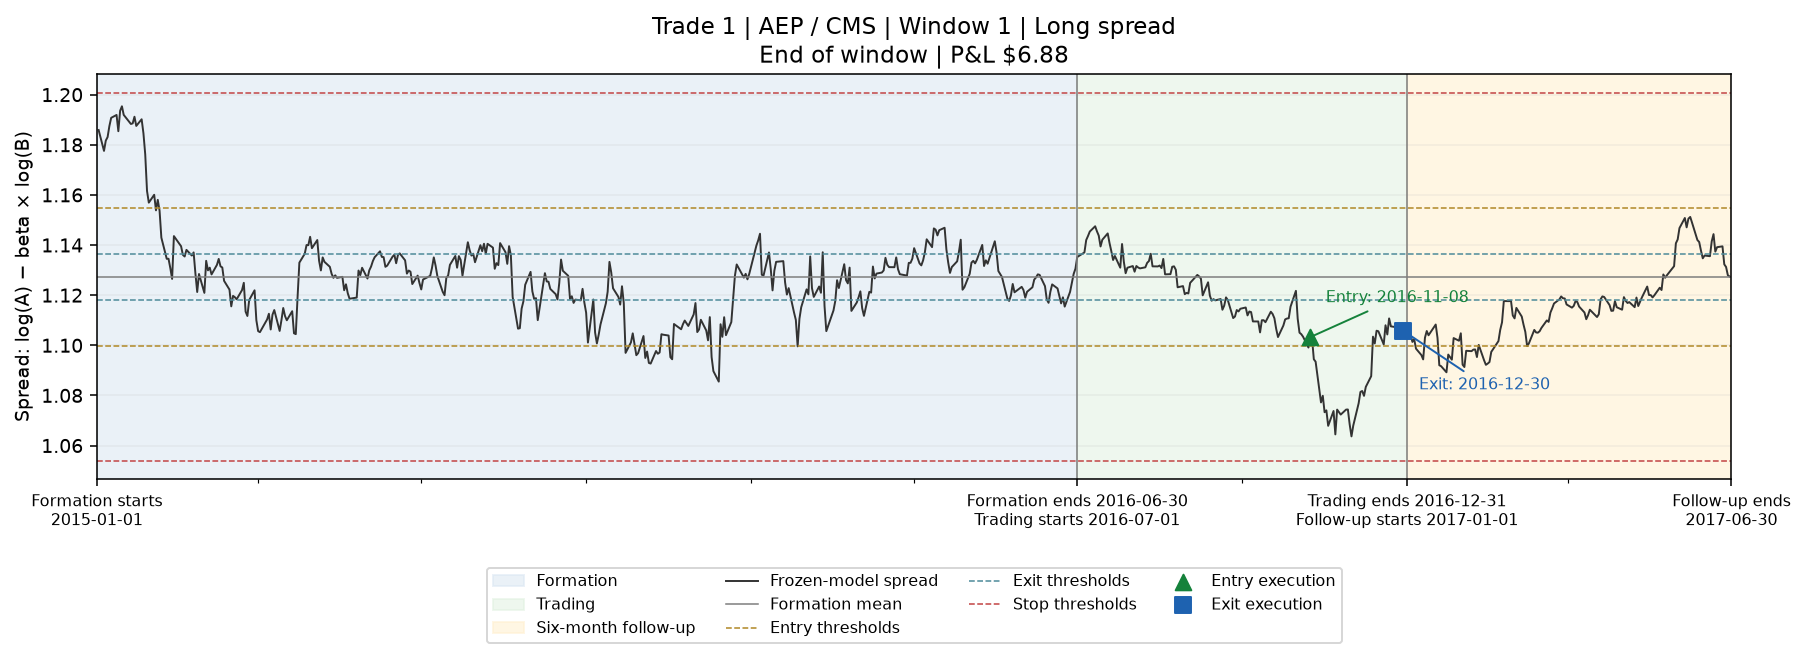

In [3]:
from IPython.display import Image
if preview_path is not None:
    display(Image(filename=str(preview_path)))
else:
    print('No trades matched the selected scope.')